As brought up over and over again by Jona and Sina, we need benchmark datasets to compare the performance of a detector with different inputs. Hence, we want some features of the PONDS data to alter (in the sense of making the signal more and more unrecognizable).

**Idea Pool**
- noise to the signal time series(white, red, ...)
- make the edges fuzzy
    - signal is getting weaker and weaker
    - signal is gauss-smoothed to the neighbour
    - ...

## Red Noise (sometimes: Brownian Noise)

Source:
- https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week5/red_noise.html
- https://atmos.washington.edu/~breth/classes/AM582/lect/lect8-notes.pdf

$$ x(t) = ax(t-\Delta t) + b\epsilon (t) $$

with $\epsilon (t)$ being white noise, $a = \rho (1)$ being the Lag(1)  (~magnitude of correlation with immediate previous step) and $b = \sqrt{1-a^2}$. The user can set the the value for $a$ accordingly. For red noise, the value is $0<a<1$. <br>
For the purpose of tuning the autocorrelation magnitude of a red-noise function as a user, it might make more sense of thinking of the $e$-folding time scale $T_e$, which indicates how fast the autocorrelation drop below $1/e = 0.368$. This is calculated with 

$$ T_e = - \frac{\Delta t}{ln(a)} \enspace ,$$

where $\Delta t$ indicates the time resolution. For our purposes, this is simply the time incerement per time-series step and is therefore set to $\Delta t = 1$.

In [108]:
import numpy as np

def lag1(Te, dt=1):
    """
    Lag-1 autocorrelation coefficient for an exponential decay process.

    Indicates after how many dt time steps the correlation has decayed to 1/e.

    Parameters
    ----------
    Te : float
        E-folding time (time for the correlation to decay to 1/e).
    dt : float, optional
        Time step size. Default is 1.
    Returns
    -------
    lag1 : float
        Lag-1 autocorrelation coefficient.
    """

    if Te < 0:
        raise ValueError("Te must be positive or zero.")
    if Te == 0:
        return 0.0
    
    lag1 = np.exp(-dt / Te)
    return lag1


lag1(1, dt=1)  # Example usage



np.float64(0.36787944117144233)

In [109]:
# implement simple red noise generator
import numpy as np

def red_noise(length,
              magnitude=1.0,
              Te=1,             # e-folding time scale
              dt=1.0            # time step size
              ) -> np.ndarray:
    """
    """

    a = lag1(Te, dt=dt)     # lag-1 autocorrelation coefficient
    b = (1 - a**2)**0.5     # coefficient for white noise term

    signal = np.random.normal(size=length)
    for i in range(1, length):
        signal[i] += a * signal[i - 1] + b * signal[i]

    return magnitude * signal

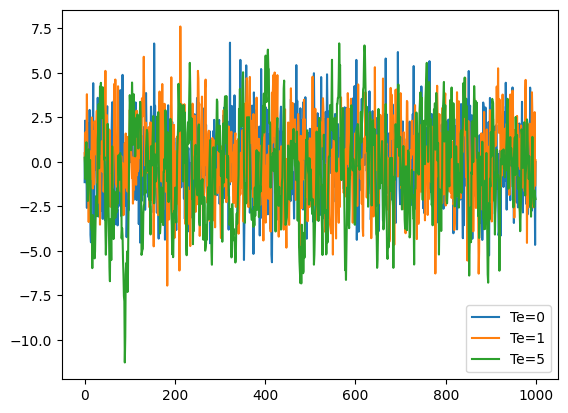

In [111]:
import matplotlib.pyplot as plt

T = 1000

Te1 = 0
ts1 = red_noise(
    T,
    Te=Te1,
    )

Te2 = 1
ts2 = red_noise(
    T,
    Te=Te2,
    )

Te3 = 5
ts3 = red_noise(
    T,
    Te=Te3,
    )

plt.plot(ts1, label='Te={}'.format(Te1))
plt.plot(ts2, label='Te={}'.format(Te2))
plt.plot(ts3, label='Te={}'.format(Te3))
plt.legend()
plt.show()

Text(0.5, 0, 'Lag')

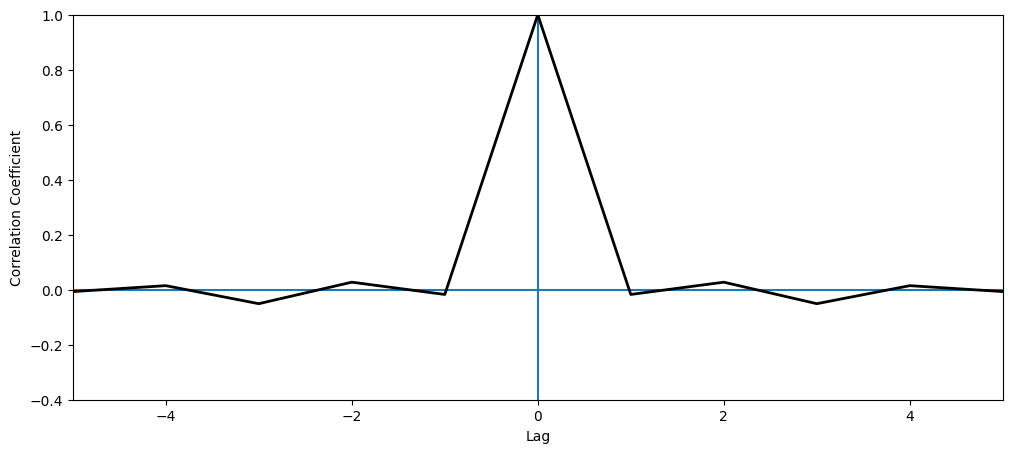

In [75]:
#np.correlate actually gives the covariance. We need to find the covariance of the deviations from the mean and then
#divide the the tau=0 covariance, i.e., the variance to get the correlation
ts = ts1
Tcorr = np.correlate((ts-np.mean(ts)),(ts-np.mean(ts))/(len(ts)*np.var(ts)),'same')

#plot the autocorrelation function
fig = plt.figure(figsize=(12,5))

# x-value for plotting
x = np.arange(0,len(ts),1)
series = [i-len(ts)/2.0 for i in x]

#plot series
plt.axhline(0)
plt.axvline(0)
plt.plot(series,Tcorr,'k',linewidth=2)
plt.xlim(-5,5)
plt.ylim(-0.4,1)
plt.ylabel('Correlation Coefficient')
plt.xlabel('Lag')

## Fuzzy Edges

- the shift signal (meaning the magnitude) becomes smaller and smaller closer to the edge of the cluster
    - this can be achieved by using a gauss-correlation

Question:<br>
If the magnitude of the shift is altered, does that mean that the cells end up at a different value in the end? 

In [3]:
import numpy as np
from ponds.shapegen import ELLIPSIS

lat_size = 10
lon_size = 10

shapegen = ELLIPSIS(
    center_lat=0,
    center_lon=0,
    ecc_lat=3,
    ecc_lon=3,
)
    
    
shape = shapegen.make_shape(
    lats = np.arange(lat_size) - lat_size // 2,
    lons = np.arange(lon_size) - lon_size // 2,
    )

print(shape)

[[False False False False False False False False False False]
 [False False False False False False False False False False]
 [False False False False False  True False False False False]
 [False False False  True  True  True  True  True False False]
 [False False False  True  True  True  True  True False False]
 [False False  True  True  True  True  True  True  True False]
 [False False False  True  True  True  True  True False False]
 [False False False  True  True  True  True  True False False]
 [False False False False False  True False False False False]
 [False False False False False False False False False False]]


**Important Idea for implementation approach:**

Reuse the correlationgen logic, but change it to a general shift-feature-offset instead of merely a shift-time-offset. The shift-time can then be choosen as a feature by the user!

ToDo:
- x make implementationtion changes for one to see if it works
- x adapt the others
- o adapt the testing
- o adapt the tutorial


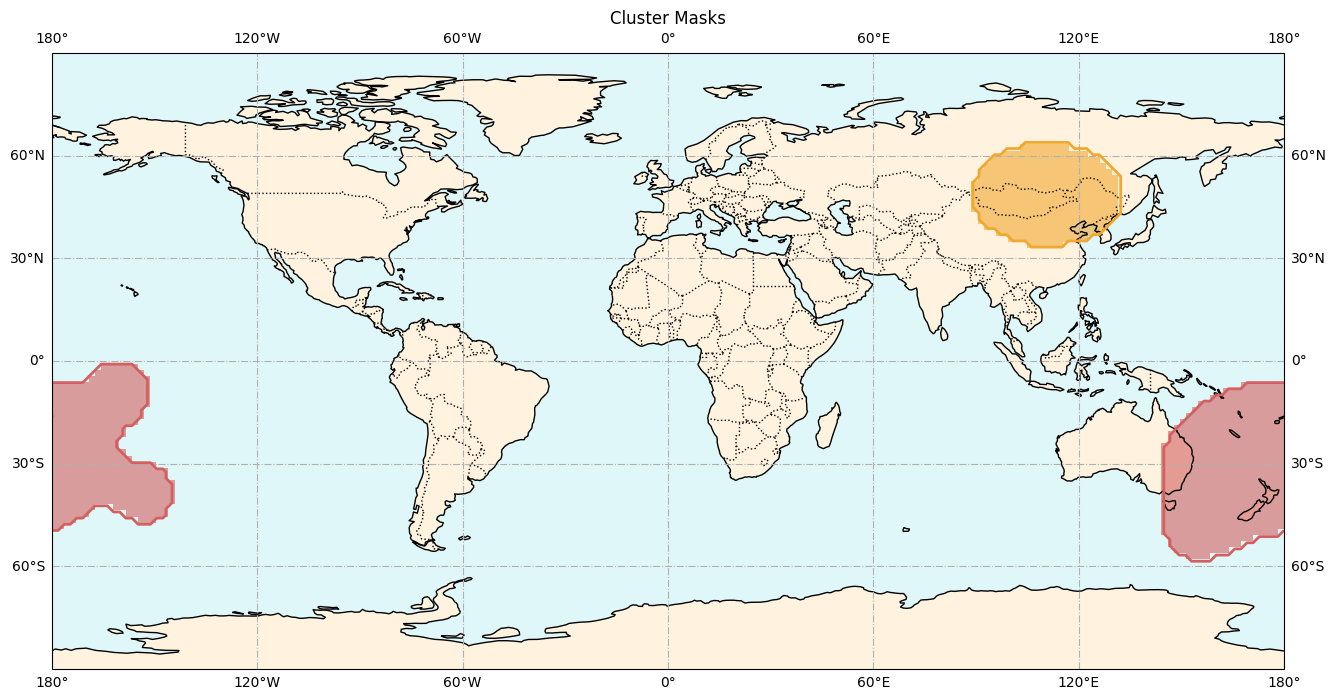

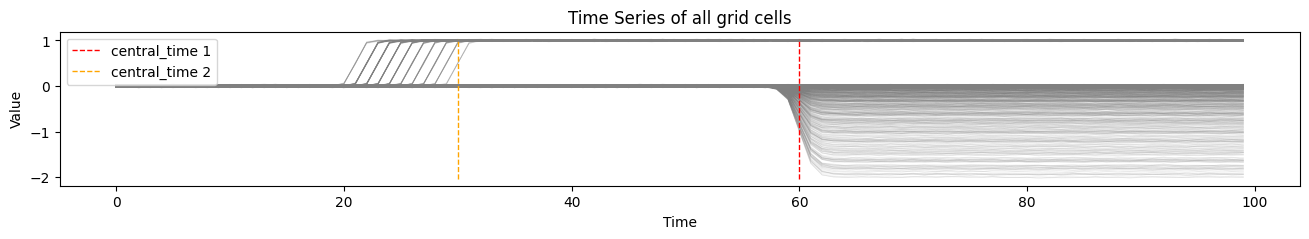

In [2]:
from ponds import PONDS, SIGMOID, BLOB, ELLIPSIS, Gauss, WhiteNoise
import numpy as np
import matplotlib.pyplot as plt

central_time_1 = 60
shift_magnitude_1 = -2
max_offset_1 = -2
central_time_2 = 30
max_offset_2 = 10

pd = PONDS(
    lat_size=101,
    lon_size=201,
    time_size=100,
)

pd.add_background(
    background_method=WhiteNoise(
        magnitude=0.01,
        background_seed=1,
    )
)

pd.add_shift(
    shift_method=SIGMOID(
        central_time=central_time_1,
        shift_magnitude=shift_magnitude_1,
    ),
    shape_method=BLOB(
        shape_seed=8,
    ),
    correlation_method=Gauss(
        feature_name="shift_magnitude",
        max_offset=max_offset_1,
    ),
)

pd.add_shift(
    shift_method=SIGMOID(
        central_time=central_time_2,
        shift_magnitude=1,
    ),
    shape_method=ELLIPSIS(
        shape_seed=5,
    ),
    correlation_method=Gauss(
        feature_name="central_time",
        max_offset=max_offset_2,
    ),
)

fig1, ax1 = pd.worldmap()

fig2, ax2 = pd.plot_all_ts(
    alpha=0.1,
)

ax2.vlines(
    x=central_time_1,
    ymin=np.min(pd.data.ts),
    ymax=np.max(pd.data.ts),
    linestyle="--",
    linewidth=1,
    color="red",
    label="central_time 1",
)
ax2.vlines(
    x=central_time_2,
    ymin=np.min(pd.data.ts),
    ymax=np.max(pd.data.ts),
    linestyle="--",
    linewidth=1,
    color="orange",
    label="central_time 2",
)
ax2.set_title("Time Series of all grid cells")
ax2.legend(loc="upper left")

plt.show()

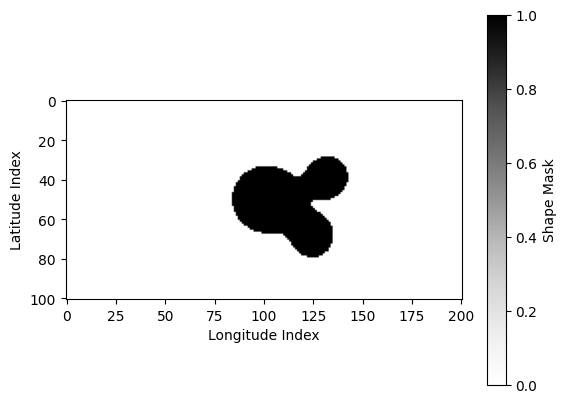

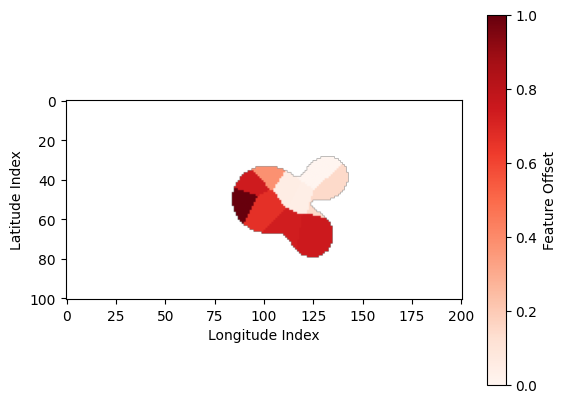

In [ ]:
from ponds import Propagating, BLOB
import matplotlib.pyplot as plt
import numpy as np

lat_size=101
lon_size=201
lats = np.arange(lat_size) - lat_size // 2
lons = np.arange(lon_size) - lon_size // 2

corr_gen = Propagating(
    feature_name="shift_magnitude",
    n_cells = 10,
    max_offset=1.0,
    corr_seed=2,
)

shape_gen = BLOB(
    center_lat=0,
    center_lon=0,
    shape_seed=8,
    #size=18,
)
shape_mask = shape_gen.make_shape(
    lats = lats,
    lons = lons,
)
plt.imshow(shape_mask, cmap='Greys')
plt.colorbar(label='Shape Mask')
plt.xlabel('Longitude Index')
plt.ylabel('Latitude Index')
plt.show()
#shape_mask = np.full((101,201), True)
#print(shape_mask)
f_os = corr_gen.make_feature_offsets(shape_mask)
f_os[~shape_mask] = None
#print(np.round(f_os,3))

plt.imshow(f_os, cmap='Reds')
plt.colorbar(label='Feature Offset')
plt.xlabel('Longitude Index')
plt.ylabel('Latitude Index')
plt.show()


/home/lukasro/Documents/TIPMIP/ponds/ponds/correlationgen.py:269: UserWarning: No random seed set for PONDS Correlation Method. Results will not be reproducible.
  warnings.warn(
/tmp/ipykernel_17681/2564744683.py:63: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend(loc="upper left")


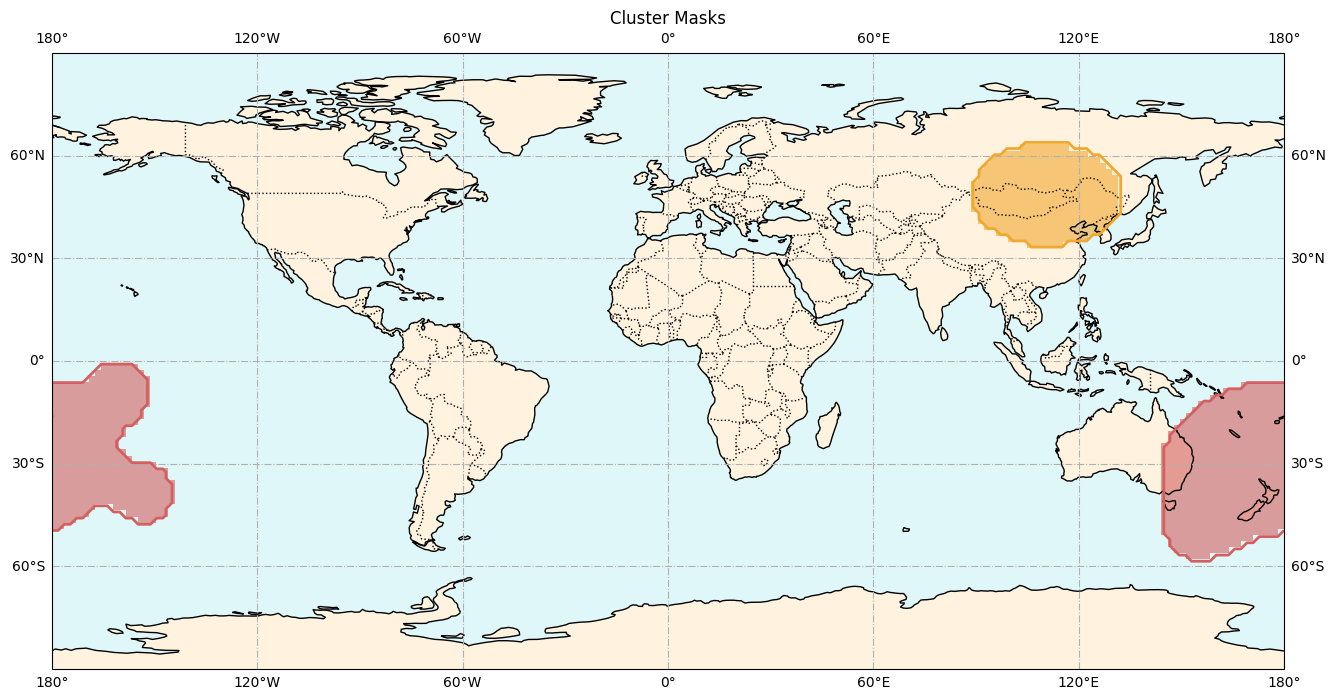

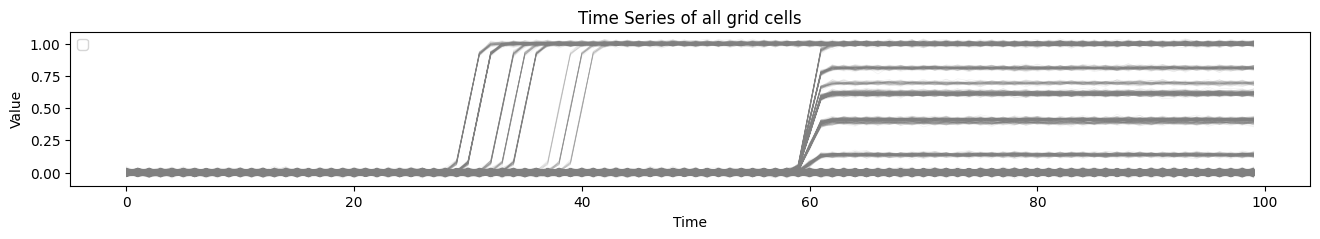

In [3]:
from ponds import PONDS, SIGMOID, BLOB, ELLIPSIS, Propagating, WhiteNoise
import numpy as np
import matplotlib.pyplot as plt

shift_magnitude_1 = 1.0
max_offset_1 = -1.0
central_time_2 = 30
max_offset_2 = 10

pd = PONDS(
    lat_size=101,
    lon_size=201,
    time_size=100,
)

pd.add_background(
    background_method=WhiteNoise(
        magnitude=0.01,
        background_seed=1,
    )
)

pd.add_shift(
    shift_method=SIGMOID(
        central_time=60,
        shift_magnitude=shift_magnitude_1,
    ),
    shape_method=BLOB(
    #center_lat=0,
    #center_lon=0,
    shape_seed=8,
),
    correlation_method=Propagating(
        feature_name="shift_magnitude",
        n_cells = 10,
        max_offset=max_offset_1,
        corr_seed=2,
    ),
)

pd.add_shift(
    shift_method=SIGMOID(
        central_time=central_time_2,
        shift_magnitude=1,
    ),
    shape_method=ELLIPSIS(
        shape_seed=5,
    ),
    correlation_method=Propagating(
        feature_name="central_time",
        n_cells = 10,
        max_offset=max_offset_2,
    ),
)

fig1, ax1 = pd.worldmap()

fig2, ax2 = pd.plot_all_ts(
    alpha=0.1,
)

ax2.set_title("Time Series of all grid cells")
ax2.legend(loc="upper left")

plt.show()

In [6]:
import inspect
from typing import get_origin, get_args, Union, Optional

def get_first_annotation_type(cls, arg_name: str):
    sig = inspect.signature(cls.__init__)
    annotation = sig.parameters[arg_name].annotation

    # Case: no union involved → return directly
    origin = get_origin(annotation)
    args = []

    # Case 1: Optional/Union style
    if origin is Union:
        args = list(get_args(annotation))

    # Case 2: Python 3.10+ pipe unions → annotation is types.UnionType
    elif hasattr(annotation, "__args__"):
        args = list(annotation.__args__)

    # No union → return annotation as is
    if not args:
        return annotation

    # Remove NoneType if present
    args = [a for a in args if a is not type(None)]

    # If something remains, return first item
    if args:
        return args[0]

    # Only NoneType existed
    return type(None)


In [ ]:
class TestClass:
    def __init__(
        self,
        x: int | float | None = None,
        y: str | int | None = None,
        z: int = 5,
        w: None | float | str = None,
        v: Optional[int] = None,
    ):
        pass


print(get_first_annotation_type(TestClass, "x"))
print(get_first_annotation_type(TestClass, "y"))
print(get_first_annotation_type(TestClass, "z"))
print(get_first_annotation_type(TestClass, "w"))
print(get_first_annotation_type(TestClass, "v"))


<class 'int'>
<class 'str'>
<class 'int'>
<class 'float'>
<class 'int'>


In [21]:
import numpy as np

a = np.array([0.99, 1.00000001, 1.5], dtype=float)
#a = [0.99,1.01, 1.5]
print(a)
# check if a is a numpy array
print(not(isinstance(a, np.ndarray)))

b = a.astype(int)
print(b)

a = a.round(0)
a = a.astype(int)
print(a)

[0.99       1.00000001 1.5       ]
False
[0 1 1]
[1 1 2]


In [35]:
rng = np.random.default_rng()
rng.uniform(-10,10,size=5).astype(float)   

array([ 4.80388494, -5.09155303, -8.00987634,  6.86985313,  0.61403098])

/home/lukasro/Documents/TIPMIP/ponds/ponds/correlationgen.py:269: UserWarning: No random seed set for PONDS Correlation Method. Results will not be reproducible.
  warnings.warn(
/tmp/ipykernel_18085/3141065303.py:63: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend(loc="upper left")


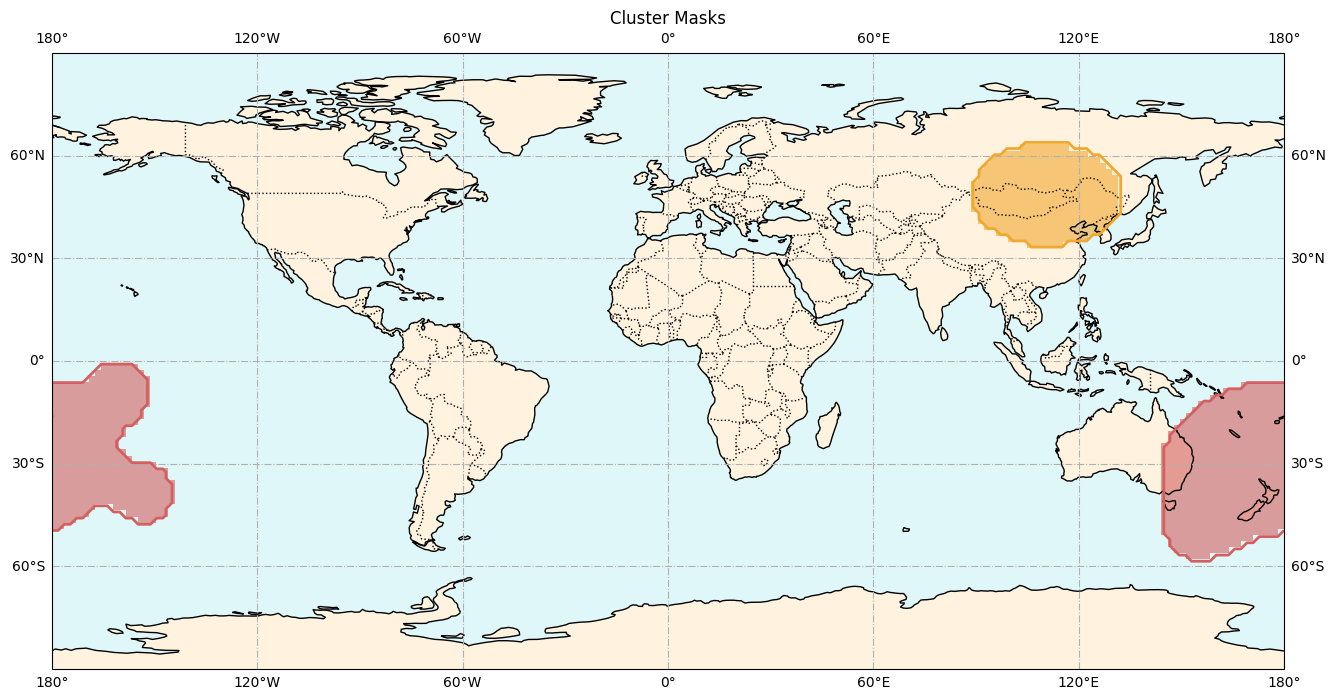

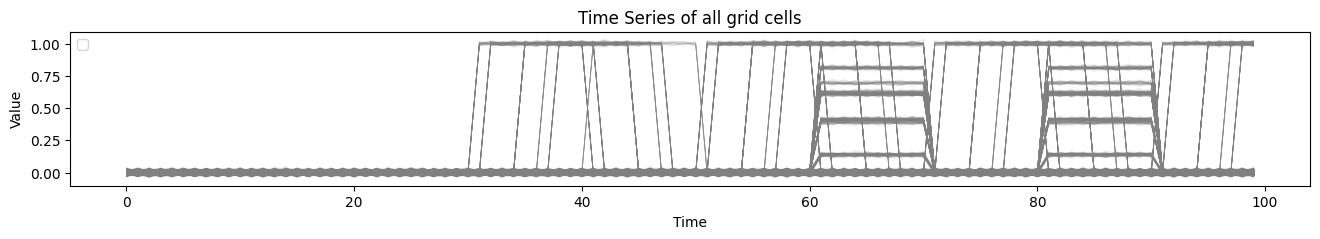

In [1]:
from ponds import PONDS, BIMODAL, BLOB, ELLIPSIS, Propagating, WhiteNoise
import numpy as np
import matplotlib.pyplot as plt

shift_magnitude_1 = 1.0
max_offset_1 = -1.0
central_time_2 = 30
max_offset_2 = 10

pd = PONDS(
    lat_size=101,
    lon_size=201,
    time_size=100,
)

pd.add_background(
    background_method=WhiteNoise(
        magnitude=0.01,
        background_seed=1,
    )
)

pd.add_shift(
    shift_method=BIMODAL(
        central_time=60,
        shift_magnitude=shift_magnitude_1,
    ),
    shape_method=BLOB(
    #center_lat=0,
    #center_lon=0,
    shape_seed=8,
),
    correlation_method=Propagating(
        feature_name="shift_magnitude",
        n_cells = 10,
        max_offset=max_offset_1,
        corr_seed=2,
    ),
)

pd.add_shift(
    shift_method=BIMODAL(
        central_time=central_time_2,
        shift_magnitude=1,
    ),
    shape_method=ELLIPSIS(
        shape_seed=5,
    ),
    correlation_method=Propagating(
        feature_name="central_time",
        n_cells = 10,
        max_offset=max_offset_2,
        corr_seed=3,
    ),
)

fig1, ax1 = pd.worldmap()

fig2, ax2 = pd.plot_all_ts(
    alpha=0.1,
)

ax2.set_title("Time Series of all grid cells")
ax2.legend(loc="upper left")

plt.show()